In [1]:
import torch
from torchvision.transforms import v2
from torchvision.transforms.v2 import InterpolationMode
from torchvision.datasets import FashionMNIST

In [2]:
import matplotlib.pyplot as plt

In [3]:
transform = v2.Compose([
    v2.Resize((64, 64), InterpolationMode.BICUBIC),
    v2.Grayscale(num_output_channels=1),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

In [4]:
dataset = FashionMNIST(root='data', train=False, download=True, transform=transform)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 213kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.7MB/s]


In [5]:
class_names = dataset.classes

In [6]:
img, class_index = dataset[1]

In [7]:
def show_image(img, class_name: str):
    plt.title(class_name)
    plt.imshow(img.permute(1, 2, 0))
    plt.axis('off')
    plt.show()

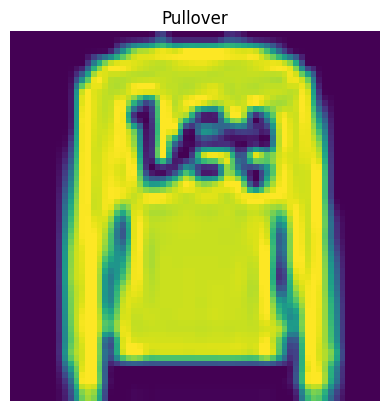

In [8]:
show_image(img, class_names[class_index])

### CLIP Preprocessing and Feature Extraction
We will import `CLIPProcessor` from the `transformers` library to prepare both our FashionMNIST image and text labels for the CLIP model. Then, we can perform a forward pass to get the aligned image and text features.

In [9]:
from transformers import CLIPProcessor, CLIPModel

In [10]:
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [11]:
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

In [12]:
# Prepare sample text labels (our dataset class names)
texts = [f"an image of a {name}" for name in class_names]

In [13]:
# The model apparently plays nicer with PIL images than Tensors
pil_img = v2.functional.to_pil_image(img)

In [14]:
# Process both image and text
inputs = processor(text=texts, images=pil_img, return_tensors="pt", padding=True)

In [15]:
# Pass the preprocessed inputs through the CLIP model
outputs = model(**inputs)

In [16]:
# Retrieve the similarity scores (logits)
logits_per_image = outputs.logits_per_image # image-to-text similarity
probs = logits_per_image.softmax(dim=-1) # softmax to get probabilities

In [17]:
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

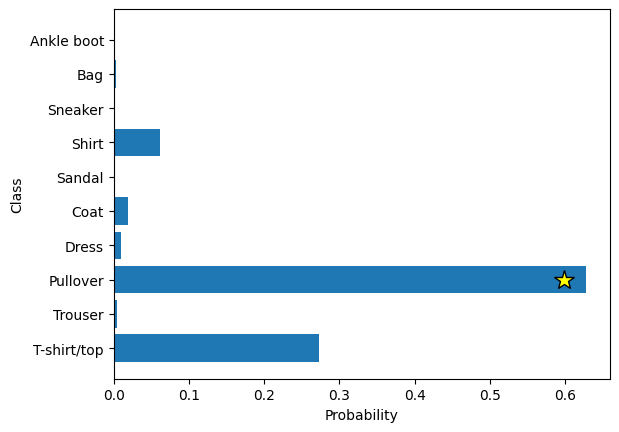

In [18]:
# Create the horizontal bar plot
bars = plt.barh(class_names, probs.detach().numpy()[0])
plt.xlabel('Probability')
plt.ylabel('Class')

# Add a yellow star on the bar that corresponds to class_index
y_position = class_index
x_position = probs.detach().numpy()[0][class_index]
plt.plot(x_position - 0.03, y_position, marker='*', color='yellow', markeredgecolor='black', markersize=15, linestyle='None')

plt.show()